# Week 4: First baseline models

I prepared 19 predictors and trained Logistic Regression, Random Forest, and XGBoost.

I used 30,000 sampled records per year to make the first run manageable. The sample keeps the diabetes ratio within each year, but gives years equal sample sizes. These are unweighted sample results, not full-data or population results.

| Step | Years | Selected records |
|---|---|---:|
| Initial fitting | 2005–2016 | 360,000 |
| Internal validation | 2017–2020 | 120,000 |
| Refit using all selected training years | 2005–2020 | 480,000 |

In [1]:
import zipfile
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import auc
from sklearn.metrics import brier_score_loss
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import CalibrationDisplay

In [2]:
zip_path = "csv.zip"
random_state = 0
max_rows_per_year = 30000
threshold = 0.50
cpu_threads = 2

with zipfile.ZipFile(zip_path) as z:
    files = {
        Path(name).name: name
        for name in z.namelist()
        if name.lower().endswith(".csv")
    }

numeric_features = [
    "bmi_00",
    "mental_health_days_00",
    "physical_health_days_00"
]

categorical_features = [
    "age_00", "sex_00", "race_00", "marital_status_00", "education_00",
    "income", "gen_health_00", "exercise_00", "smoked_100_cigarettes_00",
    "drinks_alcohol_00", "had_stroke_00", "had_heart_attack_00",
    "had_coronary_heart_disease_00", "cost_barrier_00",
    "l_checkup_00", "has_personal_doctor_00"
]

predictor_columns = numeric_features + categorical_features

target_map = {
    "Diabetic": 1,
    "Non-diabetic": 0,
    "Pre-diabetic": 0
}

feature_plan = pd.DataFrame({
    "predictor": predictor_columns,
    "treatment": ["Median and scaling"] * 3 + ["One-hot encoding"] * 16
})

display(feature_plan)
print("Number of original predictors:", len(predictor_columns))

,predictor,treatment
0,bmi_00,Median and scaling
1,mental_health_days_00,Median and scaling
2,physical_health_days_00,Median and scaling
3,age_00,One-hot encoding
4,sex_00,One-hot encoding
5,race_00,One-hot encoding
6,marital_status_00,One-hot encoding
7,education_00,One-hot encoding
8,income,One-hot encoding
9,gen_health_00,One-hot encoding


Number of original predictors: 19


## Prepare 2005–2020

I keep BMI but leave out raw weight and height because they contain related information and had unusual values in Week 3. The earlier exclusions, including high BP and cholesterol, stay outside this main baseline.

- BMI outside **12.00–99.99** becomes missing. This is a study range rule guided by CDC documentation, not a full recreation of CDC BMI. A record is not removed just because BMI is missing.
- The three numeric predictors use median imputation and scaling. Category codes use one-hot encoding, so age groups are not treated as exact ages.
- `Diabetic = 1`; `Non-diabetic` and `Pre-diabetic = 0`. Prediabetes is part of the group without reported diagnosed diabetes; this does not mean it is healthy. The processed target also does not separate pregnancy-only diabetes.
- `year` defines the split and is not a predictor. No class weighting, SMOTE, or threshold tuning is used in this first run.

`max_rows_per_year = 30000` controls the sample size. Use `None` for a later full-data run. 
Keep `random_state = 0` to reproduce this run. 
Threshold 0.50 means a predicted probability of at least 0.50 becomes class 1.


In [3]:
annual_frames = []
preparation_rows = []

with zipfile.ZipFile(zip_path) as z:
    for year in range(2005, 2021):
        annual_name = "DATASET_" + str(year) + ".csv"
        with z.open(files[annual_name]) as f:
            raw = pd.read_csv(f, low_memory=False)

        # Records need a known target for supervised learning
        missing_target_n = int(raw["diabetes"].isna().sum())
        known_target = raw["diabetes"].notna()
        clean = raw.loc[known_target].copy()
        clean["target"] = clean["diabetes"].map(target_map)
        clean["target"] = clean["target"].astype("int8")

        # This loop uses only 2005-2020, which has the older income column
        income_source = "income_00"
        maximum_income_code = 8

        original_income = clean[income_source]
        income = pd.to_numeric(original_income, errors="coerce")
        income_conversion = original_income.notna() & income.isna()
        valid_income = income.isin(range(1, maximum_income_code + 1))
        invalid_income = income.notna() & ~valid_income
        income = income.where(valid_income)
        clean["income"] = income

        # Keep the record, but replace BMI outside the study range with missing
        bmi_raw = clean["bmi_00"]
        bmi = pd.to_numeric(bmi_raw, errors="coerce")
        bmi_conversion = bmi_raw.notna() & bmi.isna()
        valid_bmi = bmi.between(12.00, 99.99)
        invalid_bmi = bmi.notna() & ~valid_bmi
        clean["bmi_00"] = bmi.where(valid_bmi)

        # Health-day counts must stay between 0 and 30
        health_values_changed = 0
        health_conversion_failures = 0
        for feature in ["mental_health_days_00", "physical_health_days_00"]:
            original_values = clean[feature]
            values = pd.to_numeric(original_values, errors="coerce")
            conversion_failed = original_values.notna() & values.isna()
            invalid_days = values.notna() & ~values.between(0, 30)
            health_conversion_failures += int(conversion_failed.sum())
            health_values_changed += int(invalid_days.sum())
            clean[feature] = values.where(values.between(0, 30))

        # Keep only the selected predictors, target, and split year
        clean["year"] = year
        selected_columns = predictor_columns + ["target", "year"]
        clean = clean[selected_columns].copy()

        # Use matching text labels across years; keep missing as its own label
        for feature in categorical_features:
            labels = clean[feature].astype("string")
            labels = labels.str.replace(r"\.0$", "", regex=True)
            labels = labels.fillna("<missing>")
            clean[feature] = labels.astype(str)

        # Smaller numeric types reduce memory use
        for feature in numeric_features:
            clean[feature] = clean[feature].astype("float32")

        rows_with_target = len(clean)
        original_diabetic_pct = clean["target"].mean() * 100

        # Select a reproducible annual sample without balancing the two classes
        if max_rows_per_year is not None:
            if len(clean) > max_rows_per_year:
                clean, unused_rows = train_test_split(
                    clean,
                    train_size=max_rows_per_year,
                    stratify=clean["target"],
                    random_state=random_state
                )
                del unused_rows

        # Record the cleaning counts and selected sample size for the report
        preparation_rows.append({
            "year": year,
            "rows_read": len(raw),
            "missing_target_removed": missing_target_n,
            "rows_with_target": rows_with_target,
            "income_conversion_failures": int(income_conversion.sum()),
            "invalid_income_to_missing": int(invalid_income.sum()),
            "bmi_conversion_failures": int(bmi_conversion.sum()),
            "bmi_range_to_missing": int(invalid_bmi.sum()),
            "health_conversion_failures": health_conversion_failures,
            "health_values_to_missing": health_values_changed,
            "selected_rows": len(clean),
            "original_diabetic_pct": original_diabetic_pct,
            "selected_diabetic_pct": clean["target"].mean() * 100
        })
        annual_frames.append(clean)
        print("Prepared", year, "— Selected rows:", len(clean))
        del raw, clean

model_data = pd.concat(annual_frames, ignore_index=True)
preparation = pd.DataFrame(preparation_rows)
del annual_frames

print("\nPreparation counts before sampling and selected sample sizes:")
display(preparation.round(3))

Prepared 2005 — Selected rows: 30000
Prepared 2006 — Selected rows: 30000
Prepared 2007 — Selected rows: 30000
Prepared 2008 — Selected rows: 30000
Prepared 2009 — Selected rows: 30000
Prepared 2010 — Selected rows: 30000
Prepared 2011 — Selected rows: 30000
Prepared 2012 — Selected rows: 30000
Prepared 2013 — Selected rows: 30000
Prepared 2014 — Selected rows: 30000
Prepared 2015 — Selected rows: 30000
Prepared 2016 — Selected rows: 30000
Prepared 2017 — Selected rows: 30000
Prepared 2018 — Selected rows: 30000
Prepared 2019 — Selected rows: 30000
Prepared 2020 — Selected rows: 30000

Preparation counts before sampling and selected sample sizes:


,year,rows_read,missing_target_removed,rows_with_target,income_conversion_failures,invalid_income_to_missing,bmi_conversion_failures,bmi_range_to_missing,health_conversion_failures,health_values_to_missing,selected_rows,original_diabetic_pct,selected_diabetic_pct
0,2005,355446,0,355446,0,0,0,42,0,0,30000,9.373,9.373
1,2006,354497,0,354497,0,0,0,61,0,0,30000,10.178,10.177
2,2007,429942,0,429942,0,0,0,41,0,0,30000,11.180,11.180
3,2008,412898,0,412898,0,0,0,70,0,0,30000,11.478,11.477
4,2009,431636,0,431636,0,0,0,50,0,0,30000,12.135,12.137
5,2010,449156,0,449156,0,0,0,85,0,0,30000,12.794,12.793
6,2011,503846,0,503846,0,0,0,94,0,0,30000,12.396,12.397
7,2012,473243,0,473243,0,0,0,82,0,0,30000,12.625,12.627
8,2013,490368,0,490368,0,0,0,105,0,0,30000,12.713,12.713
9,2014,461879,0,461879,0,0,0,92,0,0,30000,13.228,13.230


I checked 6,983,917 records from 2005–2020. No records were removed for a missing target. The BMI range rule changed **1,392 values to missing** before sampling. The saved checks found no income conversion/range problems or invalid health-day values.

I selected 30,000 records per year, for 480,000 total. The annual diabetic percentages stay close to the original percentages. The BMI count is different from Week 3 because this rule uses 12.00–99.99 and covers only 2005–2020.


## Split by year
`X` contains the predictors, and `y` contains the target. The initial model learns from 2005–2016. Data from 2017–2020 are held out to check it. All three models use the same split.


In [4]:
# Separate earlier fitting records from later validation records
fit_mask = model_data["year"].between(2005, 2016)
validation_mask = model_data["year"].between(2017, 2020)

X_fit = model_data.loc[fit_mask, predictor_columns].copy()
y_fit = model_data.loc[fit_mask, "target"].copy()
X_validation = model_data.loc[validation_mask, predictor_columns].copy()
y_validation = model_data.loc[validation_mask, "target"].copy()

# Show the exact sample sizes used in this run
split_summary = pd.DataFrame({
    "stage": ["Initial fit", "Internal validation", "Final refit"],
    "years": ["2005–2016", "2017–2020", "2005–2020"],
    "selected_rows": [len(X_fit), len(X_validation), len(model_data)],
    "diabetic_pct": [y_fit.mean() * 100,
                     y_validation.mean() * 100,
                     model_data["target"].mean() * 100]
})
display(split_summary.round(3))

print("Selected-data numeric missing percentages before imputation:")
numeric_missing = model_data[numeric_features].isna().mean() * 100
display(numeric_missing.round(3).to_frame("missing_pct"))

,stage,years,selected_rows,diabetic_pct
0,Initial fit,2005–2016,360000,12.065
1,Internal validation,2017–2020,120000,13.560
2,Final refit,2005–2020,480000,12.439


Selected-data numeric missing percentages before imputation:


,missing_pct
bmi_00,5.998
mental_health_days_00,1.737
physical_health_days_00,2.144



In the selected sample, diabetes accounts for 12.065% of initial fitting records and 13.560% of validation records. Before imputation, BMI is missing in 5.998% of the full selected sample.


## Prepare the model inputs
The numeric pipeline fills missing values using medians and then scales them. The category encoder makes one-hot columns.

In [5]:
available_numeric = X_fit[numeric_features].notna().sum()
if available_numeric.eq(0).any():
    raise ValueError("A numeric predictor is completely missing in the fitting data.")

# Learn a median for each numeric predictor from the fitting data
numeric_imputer = SimpleImputer(strategy="median")
numeric_scaler = StandardScaler()
numeric_steps = [
    ("imputer", numeric_imputer),
    ("scaler", numeric_scaler)
]
numeric_pipeline = Pipeline(steps=numeric_steps)

# A new category in validation does not stop prediction
category_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32
)

# Apply numeric steps to numeric columns and encoding to category columns
transformer_steps = [
    ("numeric", numeric_pipeline, numeric_features),
    ("category", category_encoder, categorical_features)
]
preprocessor = ColumnTransformer(
    transformers=transformer_steps,
    sparse_threshold=1.0
)

# Fit on 2005-2016 only, apply the fitted steps to validation
X_fit_ready = preprocessor.fit_transform(X_fit)
X_validation_ready = preprocessor.transform(X_validation)
X_fit_ready = X_fit_ready.astype("float32")
X_validation_ready = X_validation_ready.astype("float32")

print("Fitting matrix shape:", X_fit_ready.shape)
print("Validation matrix shape:", X_validation_ready.shape)
print("Encoded columns:", len(preprocessor.get_feature_names_out()))

Fitting matrix shape: (360000, 89)
Validation matrix shape: (120000, 89)
Encoded columns: 89


## Calculate the scores
This function repeats the same calculations for each model.

- Precision: how often predicted positives are correct.
- Recall: how many diabetic records the model finds.
- F1: combines precision and recall.
- ROC-AUC and PR-AUC: compare the probability rankings across thresholds.

Precision, recall, and F1 use threshold 0.50. PR-AUC uses the trapezoidal calculation. AP is another precision-recall summary, and Brier checks probability error.


In [6]:
def measure_model(model_name, actual, probability, fit_seconds):
    # Convert probabilities to labels using the fixed threshold
    predicted = probability >= threshold

    # Calculate the same metrics for every model
    precision = precision_score(actual, predicted, zero_division=0)
    recall = recall_score(actual, predicted, zero_division=0)
    f1 = f1_score(actual, predicted, zero_division=0)
    roc_auc = roc_auc_score(actual, probability)
    curve_precision, curve_recall, curve_thresholds = precision_recall_curve(actual, probability)
    pr_auc = auc(curve_recall, curve_precision)
    average_precision = average_precision_score(actual, probability)
    brier = brier_score_loss(actual, probability)

    scores = {
        "model": model_name,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "pr_auc_trapezoidal": pr_auc,
        "average_precision_AP": average_precision,
        "brier": brier,
        "fit_seconds": fit_seconds
    }
    return scores

# Collect the scores and probabilities for later comparison
result_rows = []
validation_probabilities = {}

## Logistic Regression


In [7]:
lr_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    random_state=random_state
)

# Fit the model and record how long fitting takes
start_time = time.perf_counter()
lr_model.fit(X_fit_ready, y_fit)
lr_fit_seconds = time.perf_counter() - start_time

# Column 1 gives the probability of the diabetic class
lr_probabilities = lr_model.predict_proba(X_validation_ready)
lr_probability = lr_probabilities[:, 1]
validation_probabilities["Logistic Regression"] = lr_probability
# Add this model to the common results table.
lr_scores = measure_model("Logistic Regression", y_validation, lr_probability, lr_fit_seconds)
result_rows.append(lr_scores)
display(pd.DataFrame([lr_scores]).round(4))
print("Iterations used:", lr_model.n_iter_)

,model,precision,recall,f1,roc_auc,pr_auc_trapezoidal,average_precision_AP,brier,fit_seconds
0,Logistic Regression,0.5647,0.1301,0.2115,0.8228,0.405,0.405,0.0969,1.5921


Iterations used: [42]


**Result:** 

ROC-AUC is 0.8228, PR-AUC is 0.4050, and recall is 0.1301. 

It has the highest recall and F1 of these three baselines, but still misses many diabetic records at threshold 0.50.

## Random Forest
I use 100 trees with limited depth for this first run. These settings have not been tuned.


In [8]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=20,
    n_jobs=cpu_threads,
    random_state=random_state
)

# Fit the model and record how long fitting takes
start_time = time.perf_counter()
rf_model.fit(X_fit_ready, y_fit)
rf_fit_seconds = time.perf_counter() - start_time

# Column 1 gives the probability of the diabetic class
rf_probabilities = rf_model.predict_proba(X_validation_ready)
rf_probability = rf_probabilities[:, 1]
validation_probabilities["Random Forest"] = rf_probability
# Add this model to the common results table.
rf_scores = measure_model("Random Forest", y_validation, rf_probability, rf_fit_seconds)
result_rows.append(rf_scores)
display(pd.DataFrame([rf_scores]).round(4))

,model,precision,recall,f1,roc_auc,pr_auc_trapezoidal,average_precision_AP,brier,fit_seconds
0,Random Forest,0.6652,0.0273,0.0525,0.8126,0.3982,0.3982,0.0991,68.5768


**Result:** 

Precision is 0.6652, but recall is only 0.0273. 

The model predicts relatively few positives. Higher precision alone does not make it the best model for this task.

## XGBoost
I use fixed starting settings and the same prepared inputs as the other models.


In [9]:
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    subsample=1.0,
    colsample_bytree=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=cpu_threads,
    random_state=random_state
)

# Fit the model and record how long fitting takes.
start_time = time.perf_counter()
xgb_model.fit(X_fit_ready, y_fit)
xgb_fit_seconds = time.perf_counter() - start_time

# Column 1 gives the probability of the diabetic class.
xgb_probabilities = xgb_model.predict_proba(X_validation_ready)
xgb_probability = xgb_probabilities[:, 1]
validation_probabilities["XGBoost"] = xgb_probability
# Add this model to the common results table.
xgb_scores = measure_model("XGBoost", y_validation, xgb_probability, xgb_fit_seconds)
result_rows.append(xgb_scores)
display(pd.DataFrame([xgb_scores]).round(4))

,model,precision,recall,f1,roc_auc,pr_auc_trapezoidal,average_precision_AP,brier,fit_seconds
0,XGBoost,0.605,0.0857,0.1501,0.8249,0.4146,0.4147,0.0962,2.8328


**Result:** 

XGBoost has the highest ROC-AUC (0.8249) and PR-AUC (0.4146) in this run. Its recall is 0.0857, lower than Logistic Regression at threshold 0.50. The ranking scores are close.

## Compare the baseline models
The table and chart show **internal validation on 2017–2020**. 

Diabetes makes up 13.56% of validation records.

All three models have low recall at threshold 0.50, even though ROC-AUC is around 0.81–0.82.


,model,precision,recall,f1,roc_auc,pr_auc_trapezoidal,average_precision_AP,brier,fit_seconds
0,Logistic Regression,0.5647,0.1301,0.2115,0.8228,0.4050,0.4050,0.0969,1.5921
1,Random Forest,0.6652,0.0273,0.0525,0.8126,0.3982,0.3982,0.0991,68.5768
2,XGBoost,0.6050,0.0857,0.1501,0.8249,0.4146,0.4147,0.0962,2.8328


Validation positive fraction / reference AP: 0.1356
Constant-probability reference Brier: 0.1172


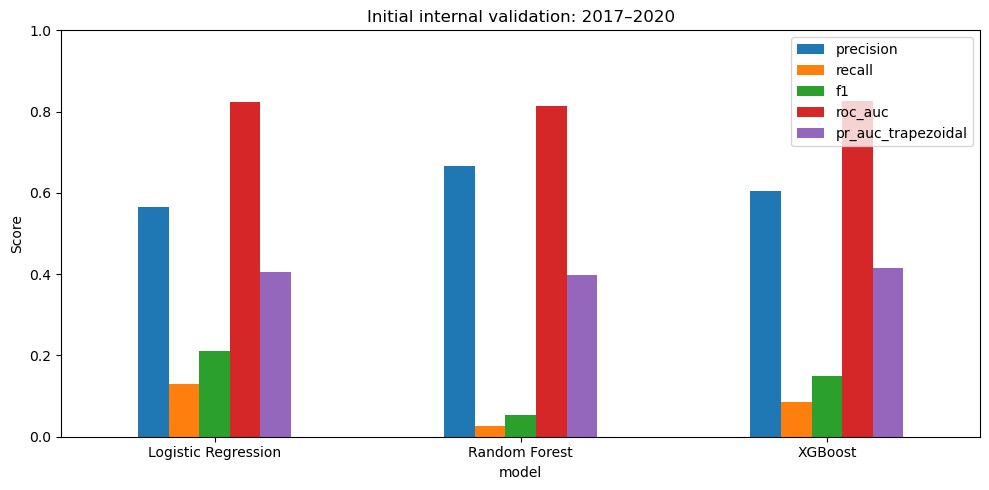

In [10]:
# Compare the saved validation results using the same threshold
validation_results = pd.DataFrame(result_rows)
display(validation_results.round(4))

validation_positive_fraction = y_validation.mean()
reference_probability = np.full(len(y_validation), validation_positive_fraction)
reference_brier = brier_score_loss(y_validation, reference_probability)
print("Validation positive fraction / reference AP:", round(validation_positive_fraction, 4))
print("Constant-probability reference Brier:", round(reference_brier, 4))

# Plot only the five main project metrics
metric_columns = ["precision", "recall", "f1", "roc_auc", "pr_auc_trapezoidal"]
comparison = validation_results.set_index("model")
comparison[metric_columns].plot(kind="bar", figsize=(10, 5))
plt.title("Initial internal validation: 2017–2020")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Confusion matrices and calibration


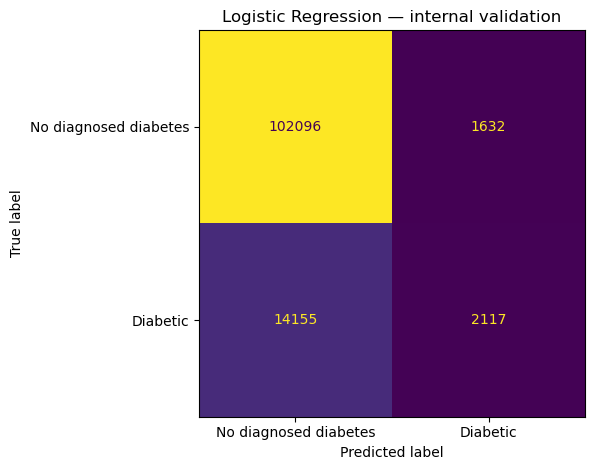

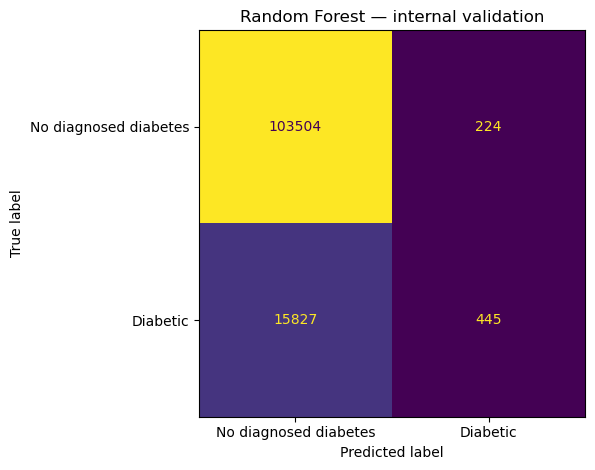

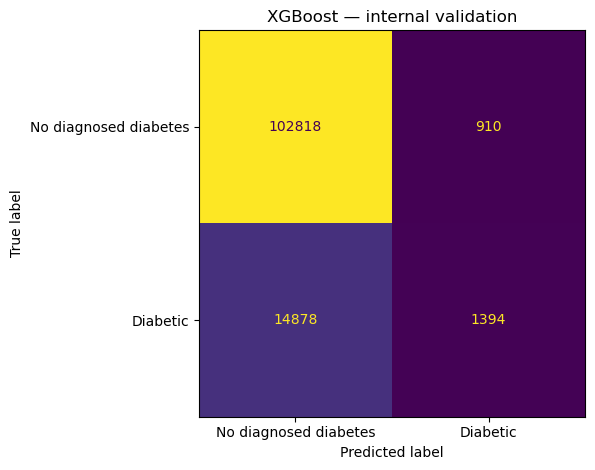

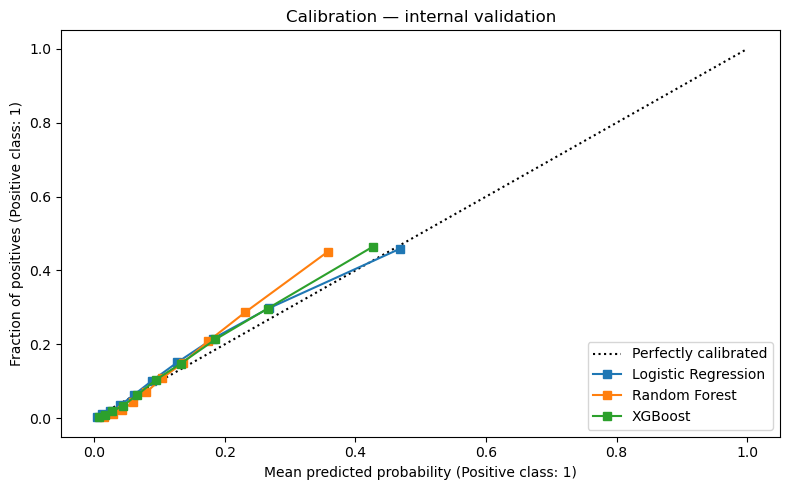

In [11]:
for model_name, probability in validation_probabilities.items():
    predicted = probability >= threshold
    ConfusionMatrixDisplay.from_predictions(
        y_validation,
        predicted,
        labels=[0, 1],
        display_labels=["No diagnosed diabetes", "Diabetic"],
        values_format="d",
        colorbar=False
    )
    plt.title(model_name + " — internal validation")
    plt.tight_layout()
    plt.show()

figure, calibration_axis = plt.subplots(figsize=(8, 5))
for model_name, probability in validation_probabilities.items():
    CalibrationDisplay.from_predictions(
        y_validation,
        probability,
        n_bins=10,
        strategy="quantile",
        name=model_name,
        ax=calibration_axis
    )
calibration_axis.set_title("Calibration — internal validation")
plt.tight_layout()
plt.show()

## Refit using the selected 2005–2020 records
After recording validation results, I refit the same model settings on all 480,000 selected records.


In [12]:
# Release intermediate fitting/validation matrices
del X_fit_ready, X_validation_ready, X_fit, X_validation

X_full = model_data[predictor_columns]
y_full = model_data["target"]
final_preprocessor = clone(preprocessor)
X_full_ready = final_preprocessor.fit_transform(X_full)
X_full_ready = X_full_ready.astype("float32")

print("Final fitting years: 2005–2020")
print("Final selected rows:", len(y_full))
print("Final encoded matrix shape:", X_full_ready.shape)

Final fitting years: 2005–2020
Final selected rows: 480000
Final encoded matrix shape: (480000, 89)


### Refit Logistic Regression


In [13]:
# Refit the same settings on the selected 2005-2020 records
final_lr = clone(lr_model)
start_time = time.perf_counter()
final_lr.fit(X_full_ready, y_full)
final_lr_seconds = time.perf_counter() - start_time
print("Final Logistic Regression fitted. Seconds:", round(final_lr_seconds, 2))
print("Iterations used:", final_lr.n_iter_)

Final Logistic Regression fitted. Seconds: 2.23
Iterations used: [44]


### Refit Random Forest


In [14]:
# Refit the same settings on the selected 2005-2020 records.
final_rf = clone(rf_model)
start_time = time.perf_counter()
final_rf.fit(X_full_ready, y_full)
final_rf_seconds = time.perf_counter() - start_time
print("Final Random Forest fitted. Seconds:", round(final_rf_seconds, 2))

Final Random Forest fitted. Seconds: 99.53


### Refit XGBoost


In [15]:
# Refit the same settings on the selected 2005-2020 records.
final_xgb = clone(xgb_model)
start_time = time.perf_counter()
final_xgb.fit(X_full_ready, y_full)
final_xgb_seconds = time.perf_counter() - start_time
print("Final XGBoost fitted. Seconds:", round(final_xgb_seconds, 2))

final_fit_summary = pd.DataFrame({
    "model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "training_years": ["2005–2020", "2005–2020", "2005–2020"],
    "selected_rows": [len(y_full), len(y_full), len(y_full)],
    "fit_seconds": [final_lr_seconds, final_rf_seconds, final_xgb_seconds]
})
display(final_fit_summary.round(2))

Final XGBoost fitted. Seconds: 3.62


,model,training_years,selected_rows,fit_seconds
0,Logistic Regression,2005–2020,480000,2.23
1,Random Forest,2005–2020,480000,99.53
2,XGBoost,2005–2020,480000,3.62


## Summary
[CDC 2024 calculated variables](https://www.cdc.gov/brfss/annual_data/2024/pdf/2024-calculated-variables-version4-508.pdf), page 13, guides the BMI range check.

I applied the BMI range rule, prepared 19 predictors, and ran three baseline models. I used 360,000 records for initial fitting, 120,000 for internal validation, and 480,000 for the final refits.

The main issue is low recall at threshold 0.50. Next week I will try a small number of threshold and model-setting changes, using validation only. I will also compare a simple class-weighting option. I will keep the 2021–2024 tests for later, after the choices are settled.
